## Import libraries

In [1]:
import pyocto
import numpy as np
import pandas as pd
import datetime
import matplotlib.pyplot as plt

## Load picks obtained from `PhaseNO`

In [2]:
df_picks=pd.read_json('/home/msseo/works/72.2025_Imsil_swarm/3.PhaseNO/results/picks/picks_2025-11-02T00:00.json')
prob_threshold=0.5
df_picks=df_picks[df_picks["prob"]>=prob_threshold]
df_picks.head()

,id,timestamp,prob,amp,type
1,KS.CHOA.HG.2025-11-02T00:00.mseed,2025-11-02 00:02:58.688,0.524319,1.474493,p
4,KS.CHOA.HG.2025-11-02T00:00.mseed,2025-11-02 00:04:16.568,0.570843,2.328357,p
14,KS.CHOA.HG.2025-11-02T00:00.mseed,2025-11-02 00:24:19.808,0.973043,2.009039,p
18,KS.CHOA.HG.2025-11-02T00:00.mseed,2025-11-02 00:30:55.648,0.701745,2.088338,p
21,KS.CHOA.HG.2025-11-02T00:00.mseed,2025-11-02 00:37:54.508,0.677659,1.814923,p


In [3]:
len(df_picks)

10970

In [4]:
np.min(df_picks["prob"]), np.max(df_picks["prob"])

(0.5000368952751161, 0.9971066117286681)

### Convert the pick format to that required by `PyOcto`

In [5]:
picks_pyocto=df_picks.assign(
    station=df_picks['id'].str.split('.').str[0:2].str.join('.') + '.',
    phase=df_picks['type'].str.upper(),
    time=pd.to_datetime(df_picks['timestamp'])
)

In [6]:
picks_pyocto=picks_pyocto[['station', 'phase', 'time']]
picks_pyocto

,station,phase,time
1,KS.CHOA.,P,2025-11-02 00:02:58.688
4,KS.CHOA.,P,2025-11-02 00:04:16.568
14,KS.CHOA.,P,2025-11-02 00:24:19.808
18,KS.CHOA.,P,2025-11-02 00:30:55.648
21,KS.CHOA.,P,2025-11-02 00:37:54.508
...,...,...,...
24231,KS.TAIA.,S,2025-11-02 23:44:50.738
24233,KS.TAIA.,S,2025-11-02 23:47:13.278
24234,KS.TAIA.,S,2025-11-02 23:51:46.448
24237,KS.TAIA.,S,2025-11-02 23:55:25.788


## Load station list

In [9]:
station_table= pd.read_csv('/home/msseo/works/72.2025_Imsil_swarm/3.PhaseNO/stations.csv',sep=',')
station_table["st_id"]=station_table["id"].apply(lambda x: x.split('.')[0]+'.'+x.split('.')[1]+'.')

In [10]:
station_table

,id,network,station,channel,latitude,longitude,elevation,unit,component,response,st_id
0,KS.CHOA..HG,KS,CHOA,HG,35.84070,127.11710,102.0,m/s**2,"E,N,Z",NaN,KS.CHOA.
1,KS.GKSA..HG,KS,GKSA,HG,35.23040,127.22510,180.0,m/s**2,"E,N,Z",NaN,KS.GKSA.
2,KS.IMSB..HH,KS,IMSB,HH,35.61250,127.28550,313.0,m/s,"E,N,Z",NaN,KS.IMSB.
3,KS.JASA..HG,KS,JASA,HG,35.65700,127.52040,408.0,m/s**2,"E,N,Z",NaN,KS.JASA.
4,KS.JEU2..EL,KS,JEU2,EL,35.49330,126.92960,171.0,m/s,"E,N,Z",NaN,KS.JEU2.
5,KS.JLSA..HG,KS,JLSA,HG,35.35750,127.64800,536.0,m/s**2,"E,N,Z",NaN,KS.JLSA.
6,KS.MALA..HG,KS,MALA,HG,35.74450,127.34780,308.0,m/s**2,"E,N,Z",NaN,KS.MALA.
7,KS.NAWB..HH,KS,NAWB,HH,35.42130,127.39640,185.0,m/s,"E,N,Z",NaN,KS.NAWB.
8,KS.SIDA..HG,KS,SIDA,HG,35.67362,127.14138,211.0,m/s**2,"E,N,Z",NaN,KS.SIDA.
9,KS.SUCA..HG,KS,SUCA,HG,35.37360,127.13860,142.0,m/s**2,"E,N,Z",NaN,KS.SUCA.


### Convert the station format to that required by `PyOcto`

In [11]:
station_pyocto=station_table[['st_id', 'longitude', 'latitude', 'elevation']]
station_pyocto=station_pyocto.rename(columns = {'st_id': 'id'})
station_pyocto

,id,longitude,latitude,elevation
0,KS.CHOA.,127.11710,35.84070,102.0
1,KS.GKSA.,127.22510,35.23040,180.0
2,KS.IMSB.,127.28550,35.61250,313.0
3,KS.JASA.,127.52040,35.65700,408.0
4,KS.JEU2.,126.92960,35.49330,171.0
5,KS.JLSA.,127.64800,35.35750,536.0
6,KS.MALA.,127.34780,35.74450,308.0
7,KS.NAWB.,127.39640,35.42130,185.0
8,KS.SIDA.,127.14138,35.67362,211.0
9,KS.SUCA.,127.13860,35.37360,142.0


## Velocity models (1D, SKP)

In [10]:
layers=pd.read_csv("./kim1983.csv")
layers

,depth,vp,vp_grad,vs,vs_grad,x,y
0,0.0,5.98,0.0,3.40,0.0,1.0,0.0
1,15.0,6.38,0.0,3.79,0.0,1.0,0.0
2,32.0,7.95,0.0,4.58,0.0,1.0,0.0


In [11]:
model_path="velocity_model"
pyocto.VelocityModel1D.create_model(layers, 1., 100, 100, model_path)

In [12]:
velocity_model=pyocto.VelocityModel1D(model_path, tolerance=1.0)

## Configure associator

In [13]:
associator=pyocto.OctoAssociator.from_area(
    lat=(35., 36.),
    lon=(126.5, 128.0),
    zlim=(0, 35),
    time_before=300,
    velocity_model=velocity_model,
    n_picks=8,
    n_p_and_s_picks=4,
)

The required number of P picks per event (3) is lower than the number of stations with both P and S pick (4). The effective number of P picks required will be 4.
The required number of S picks per event (3) is lower than the number of stations with both P and S pick (4). The effective number of S picks required will be 4.


In [14]:
associator.crs

<Projected CRS: +proj=tmerc +lat_0=35.5 +lon_0=127.25 +units=km +t ...>
Name: unknown
Axis Info [cartesian]:
- E[east]: Easting (kilometre)
- N[north]: Northing (kilometre)
Area of Use:
- undefined
Coordinate Operation:
- name: unknown
- method: Transverse Mercator
Datum: World Geodetic System 1984
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [15]:
associator.transform_stations(station_pyocto)
station_pyocto

,id,longitude,latitude,elevation,x,y,z
0,KS.CHOA.,127.11710,35.84070,102.0,-12.006810,37.809808,-0.102
1,KS.GKSA.,127.22510,35.23040,180.0,-2.266686,-29.911102,-0.180
2,KS.IMSB.,127.28550,35.61250,313.0,3.216396,12.482545,-0.313
3,KS.JASA.,127.52040,35.65700,408.0,24.485427,17.453020,-0.408
4,KS.JEU2.,126.92960,35.49330,171.0,-29.072161,-0.696167,-0.171
5,KS.JLSA.,127.64800,35.35750,536.0,36.174058,-15.737448,-0.536
6,KS.MALA.,127.34780,35.74450,308.0,8.846366,27.132178,-0.308
7,KS.NAWB.,127.39640,35.42130,185.0,13.295731,-8.721844,-0.185
8,KS.SIDA.,127.14138,35.67362,211.0,-9.833777,19.268811,-0.211
9,KS.SUCA.,127.13860,35.37360,142.0,-10.123066,-14.018205,-0.142


In [16]:
picks_pyocto["time"]=picks_pyocto["time"].apply(lambda x: x.timestamp())
picks_pyocto

,station,phase,time
1,KS.CHOA.,P,1.762042e+09
4,KS.CHOA.,P,1.762042e+09
14,KS.CHOA.,P,1.762043e+09
18,KS.CHOA.,P,1.762043e+09
21,KS.CHOA.,P,1.762044e+09
...,...,...,...
24231,KS.TAIA.,S,1.762127e+09
24233,KS.TAIA.,S,1.762127e+09
24234,KS.TAIA.,S,1.762128e+09
24237,KS.TAIA.,S,1.762128e+09


In [17]:
station_pyocto

,id,longitude,latitude,elevation,x,y,z
0,KS.CHOA.,127.11710,35.84070,102.0,-12.006810,37.809808,-0.102
1,KS.GKSA.,127.22510,35.23040,180.0,-2.266686,-29.911102,-0.180
2,KS.IMSB.,127.28550,35.61250,313.0,3.216396,12.482545,-0.313
3,KS.JASA.,127.52040,35.65700,408.0,24.485427,17.453020,-0.408
4,KS.JEU2.,126.92960,35.49330,171.0,-29.072161,-0.696167,-0.171
5,KS.JLSA.,127.64800,35.35750,536.0,36.174058,-15.737448,-0.536
6,KS.MALA.,127.34780,35.74450,308.0,8.846366,27.132178,-0.308
7,KS.NAWB.,127.39640,35.42130,185.0,13.295731,-8.721844,-0.185
8,KS.SIDA.,127.14138,35.67362,211.0,-9.833777,19.268811,-0.211
9,KS.SUCA.,127.13860,35.37360,142.0,-10.123066,-14.018205,-0.142


## Perform association

In [18]:
events_1d, assignments_1d=associator.associate(picks_pyocto, station_pyocto)

## Check association results

In [19]:
print("1D model - Events: ", len(events_1d), "Picks: ", events_1d["picks"].sum())

1D model - Events:  39 Picks:  574


In [20]:
associator.transform_events(events_1d)
events_1d["time"]=events_1d["time"].apply(datetime.datetime.fromtimestamp, tz=datetime.timezone.utc)
events_1d

,idx,time,x,y,z,picks,latitude,longitude,depth
0,0,2025-11-02 03:06:07.098809+00:00,5.883866,6.648589,22.421875,9,35.559907,127.314899,22.421875
1,1,2025-11-02 04:13:26.740459+00:00,12.302628,-30.710996,9.296875,14,35.223117,127.385135,9.296875
2,2,2025-11-02 06:20:48.101702+00:00,11.232835,-5.514996,4.921875,8,35.450229,127.373730,4.921875
3,3,2025-11-02 07:36:46.580163+00:00,1.604691,12.730382,30.078125,8,35.614738,127.267712,30.078125
4,4,2025-11-02 10:42:33.640302+00:00,-15.512010,3.173279,0.546875,8,35.528480,127.078970,0.546875
5,5,2025-11-02 12:05:49.221508+00:00,-14.442216,0.566797,0.546875,8,35.505004,127.090811,0.546875
6,6,2025-11-02 20:04:19.720213+00:00,3.744278,5.779762,13.671875,10,35.552086,127.291295,13.671875
7,7,2025-11-02 20:05:39.472967+00:00,3.744278,5.779762,13.671875,17,35.552086,127.291295,13.671875
8,8,2025-11-02 20:06:25.059727+00:00,5.883866,5.779762,13.671875,14,35.552076,127.314893,13.671875
9,9,2025-11-02 20:10:44.458687+00:00,3.744278,5.779762,12.578125,19,35.552086,127.291295,12.578125


In [21]:
events_1d.to_csv(f"/home/msseo/works/72.2025_Imsil_swarm/4.PyOcto/251102/pyocto_kim1983_prob{prob_threshold}.csv", index=False)

In [22]:
assignments_1d.to_csv(f"/home/msseo/works/72.2025_Imsil_swarm/4.PyOcto/251102/pyocto_assignment_kim1983_prob{prob_threshold}.csv", index=False)

In [23]:
# Known hypocenter of Imsil M 1.9 event
evla, evlo=35.5498, 127.2947

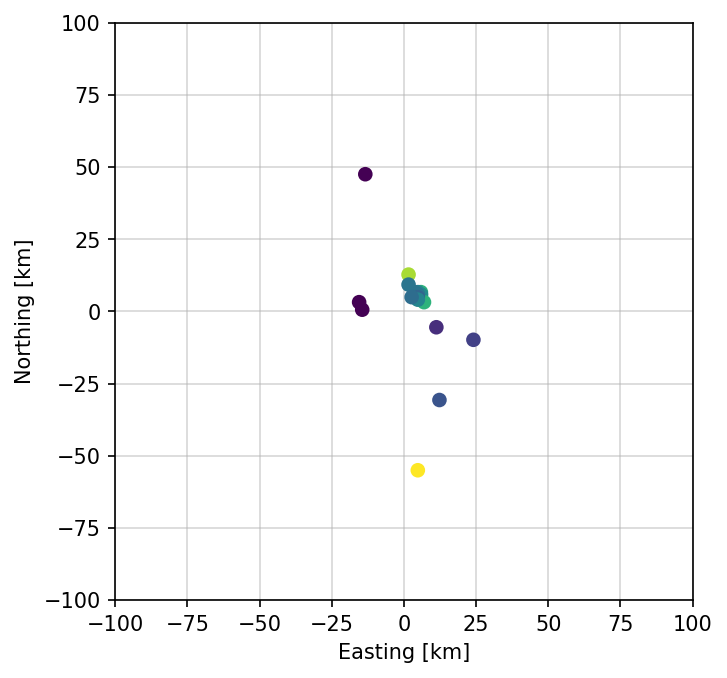

In [24]:
fig=plt.figure(figsize=(5, 5), dpi=150)
ax=fig.add_subplot()
ax.set_aspect("equal")
ax.scatter(events_1d["x"], events_1d["y"], c=events_1d["z"], zorder=10)
ax.grid(alpha=0.5)
ax.set_xlabel("Easting [km]")
ax.set_ylabel("Northing [km]")
ax.set_xlim(-100, 100)
ax.set_ylim(-100, 100)
plt.show();

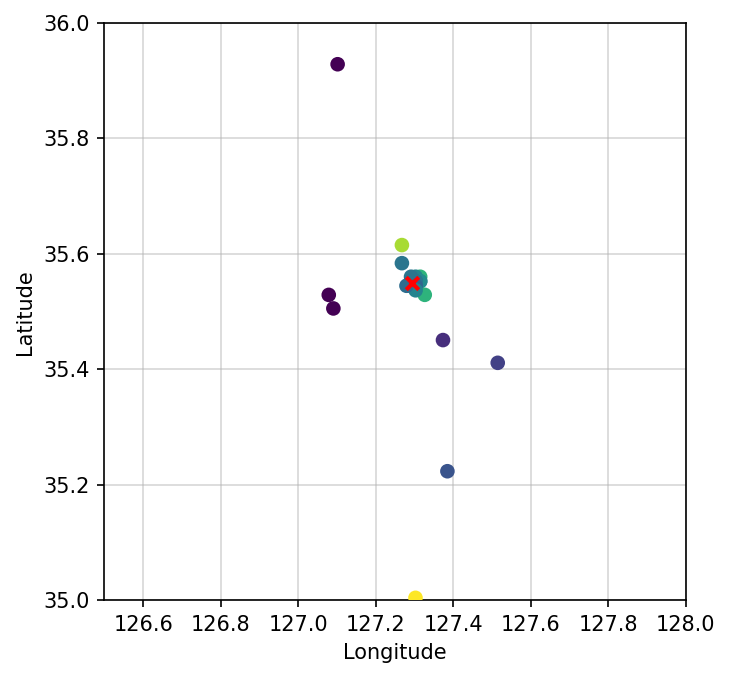

In [25]:
fig=plt.figure(figsize=(5, 5), dpi=150)
ax=fig.add_subplot()
ax.scatter(events_1d["longitude"], events_1d["latitude"], c=events_1d["z"], zorder=10)
ax.scatter(evlo, evla, color="r", marker="x", lw=2, zorder=20)
ax.grid(alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(126.5, 128.0)
ax.set_ylim(35.0, 36.0)
plt.show();

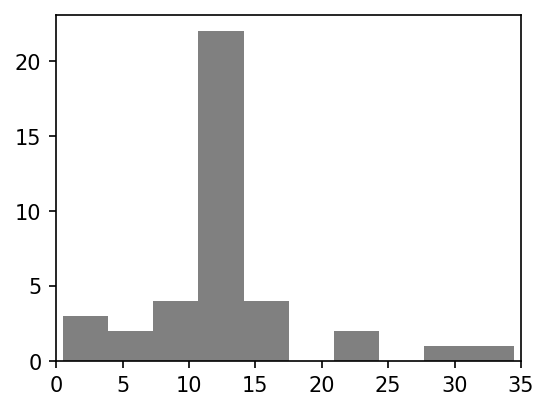

In [26]:
plt.figure(figsize=(4, 3), dpi=150)
plt.hist(events_1d["depth"], color="gray")
plt.xlim(0, 35)
plt.show();